# Project — Search Engine and Topic Classifier for French Environmental Texts
**French Environmental Text Intelligence** (Group 3, French)

**What this notebook does, in plain words.** This is the goal of our project. Everything from the weekly notebooks comes together here:
1. **Search (information retrieval):** the user types a question in French (*énergie solaire*, *polluants émis par les voitures*) and gets the most relevant documents of our corpus.
2. **Classification:** the computer decides automatically whether a text is about *emissions*, *renewable energy*, *pollution* or *climate policy*.

Both use **TF-IDF**: each document becomes a list of numbers, one per word. A word gets a high weight when it is frequent **in this document** (TF = term frequency) but rare **in the other documents** (IDF = inverse document frequency). So *éolienne* weighs a lot in a text about wind power, and *de* weighs almost nothing. (TF-IDF is officially covered later in the course; this notebook is a preview that shows what the earlier weeks are for.)

We follow the 5 steps of the NLP pipeline from Week 1: analyse the task → prepare the data → choose the features → apply an algorithm → **evaluate**. For the features we compare the preprocessing choices of the earlier weeks: plain words, stop-word removal (Week 6), stemming and lemmatization (Week 3).

## Setup: the corpus and four preprocessing variants

In [1]:
# !pip install spacy nltk scikit-learn pandas matplotlib
# !python -m spacy download fr_core_news_md
import numpy as np
import pandas as pd
import spacy
from collections import Counter
from nltk.stem.snowball import FrenchStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
from nlp_utils import load_corpus, preprocess, CATEGORIES

nlp = spacy.load('fr_core_news_md', disable=['ner'])
stemmer = FrenchStemmer()
docs = load_corpus()
spacy_docs = list(nlp.pipe([d['text'] for d in docs]))
titles = [d['title'] for d in docs]
labels = [d['category'] for d in docs]
kinds = [d['kind'] for d in docs]
print(len(docs), 'documents |', Counter(labels), '|', Counter(kinds))

# Four ways to turn a text into terms (the choices of Weeks 2, 3 and 6)
VARIANTS = {
    'words':            lambda doc: [t.lower_ for t in doc if t.is_alpha],                         # Week 2: tokens only
    'words - stopwords': lambda doc: [t.lower_ for t in doc if t.is_alpha and not t.is_stop],       # + Week 6
    'stems - stopwords': lambda doc: [stemmer.stem(w) for w in preprocess(doc)],                    # + Week 3 stemming
    'lemmas - stopwords': lambda doc: preprocess(doc),                                               # + Week 3 lemmatization
}
terms = {name: [f(d) for d in spacy_docs] for name, f in VARIANTS.items()}
for name, t in terms.items():
    print(f'{name:20s} {len({w for ws in t for w in ws}):5d} different terms')

107 documents | Counter({'politique_climatique': 28, 'energies_renouvelables': 27, 'emissions': 26, 'pollution': 26}) | Counter({'encyclopedia': 81, 'news': 16, 'discussion': 8, 'legal': 2})
words                 4890 different terms
words - stopwords     4614 different terms
stems - stopwords     3012 different terms
lemmas - stopwords    3495 different terms


---
# Part A — The search engine
The query goes through **the same preprocessing** as the documents, becomes a TF-IDF vector, and the documents are ranked by **cosine similarity** (how much the two vectors point in the same direction, from 0 to 1).

In [2]:
class SearchEngine:
    def __init__(self, variant):
        self.variant = variant
        self.vectorizer = TfidfVectorizer(analyzer=lambda x: x, sublinear_tf=True)   # terms are already prepared
        self.matrix = self.vectorizer.fit_transform(terms[variant])

    def scores(self, query):
        q = self.vectorizer.transform([VARIANTS[self.variant](nlp(query))])
        return linear_kernel(q, self.matrix).ravel()                                  # cosine (vectors are normalized)

    def search(self, query, k=5):
        s = self.scores(query)
        top = np.argsort(-s)[:k]
        return pd.DataFrame({'score': s[top].round(3), 'file': [docs[i]['file'] for i in top],
                             'kind': [kinds[i] for i in top], 'title': [titles[i][:70] for i in top]})

engine = SearchEngine('lemmas - stopwords')
engine.search('énergie solaire')

,score,file,kind,title
0,0.274,text46.txt,encyclopedia,Énergie solaire thermique
1,0.253,text50.txt,encyclopedia,Énergie solaire
2,0.236,text10.txt,encyclopedia,Énergie solaire photovoltaïque
3,0.195,text83.txt,news,Nucléaire : 69 % des Français pensent à tort q...
4,0.187,text56.txt,encyclopedia,Stockage de l'énergie


In [3]:
engine.search('polluants émis par les voitures')

,score,file,kind,title
0,0.130,text17.txt,encyclopedia,Pollution de l'air
1,0.120,text101.txt,discussion,Discussion:Pollution de l'air
2,0.097,text89.txt,news,Chine : Pékin en alerte rouge pollution
3,0.094,text62.txt,encyclopedia,Ozone troposphérique
4,0.091,text83.txt,news,Nucléaire : 69 % des Français pensent à tort q...


In [4]:
engine.search("Est-ce que le charbon est une énergie renouvelable ?")

,score,file,kind,title
0,0.286,text83.txt,news,Nucléaire : 69 % des Français pensent à tort q...
1,0.229,text09.txt,encyclopedia,Énergie renouvelable
2,0.207,text53.txt,encyclopedia,Bois énergie
3,0.183,text16.txt,encyclopedia,Transition énergétique
4,0.170,text50.txt,encyclopedia,Énergie solaire


## How good is the search? An evaluation with hand-made relevance judgments
A search engine is evaluated like the lecture's IR task: for test queries we decide **by hand** which documents are relevant (we wrote these judgments **before** running the engine, by looking only at the titles and topics). Then we measure:
- **Precision@5:** of the 5 documents shown, how many are relevant? (what the user sees)
- **Recall@10:** of all the relevant documents, how many are in the top 10? (did we miss anything?)
- **MRR** (mean reciprocal rank): 1 if the first result is relevant, 1/2 if the first relevant one is second, etc.

Some queries deliberately use **other word forms** than the documents (*polluants émis* versus *pollution, émissions*; *biocarburants* versus *biocarburant*), to test normalization.

In [5]:
# query -> relevant files (decided by hand, before running the engine)
QRELS = {
    'énergie solaire':                          [10, 46, 50, 51, 55, 100],
    'éoliennes en mer et parcs éoliens':        [11, 45, 88, 99, 107],
    'marée noire et pétrole sur les côtes':     [23, 90, 91, 92, 102],
    "pollution de l'air dans les villes":       [17, 21, 62, 64, 65, 89, 101],
    'taxe sur le carbone':                      [28, 93, 103],
    'accords internationaux sur le climat':     [25, 26, 31, 73, 80, 95, 96, 104],
    'émissions de méthane':                     [2, 98],
    'plastique dans les océans':                [20, 59],
    "pesticides et pollution de l'eau":         [18, 58, 60, 67],
    'biocarburants et biogaz':                  [14, 47, 48, 53, 54],
    'neutralité carbone en 2050':               [6, 35, 69, 81, 84],
    'santé et métaux lourds':                   [61, 68],
    'polluants émis par les voitures':          [17, 21, 64, 66, 82],
    "stockage de l'électricité renouvelable":   [56, 85, 86],
}
QRELS = {q: {f'text{n:02d}.txt' for n in rel} for q, rel in QRELS.items()}
files = [d['file'] for d in docs]

def evaluate(engine, k_p=5, k_r=10):
    rows = []
    for q, rel in QRELS.items():
        ranked = [files[i] for i in np.argsort(-engine.scores(q))]
        p = sum(f in rel for f in ranked[:k_p]) / k_p
        r = sum(f in rel for f in ranked[:k_r]) / len(rel)
        rr = next((1 / (i + 1) for i, f in enumerate(ranked) if f in rel), 0)
        rows.append({'query': q, 'P@5': p, 'R@10': r, 'RR': rr})
    return pd.DataFrame(rows).set_index('query')

per_query = {name: evaluate(SearchEngine(name)) for name in VARIANTS}
summary = pd.DataFrame({name: res.mean() for name, res in per_query.items()}).T.round(3)
summary.columns = ['Precision@5', 'Recall@10', 'MRR']
summary

,Precision@5,Recall@10,MRR
words,0.471,0.679,0.946
words - stopwords,0.443,0.679,0.946
stems - stopwords,0.514,0.794,0.952
lemmas - stopwords,0.557,0.762,0.946


In [6]:
# Per query: Precision@5 of each variant
pd.DataFrame({name: res['P@5'] for name, res in per_query.items()})

,words,words - stopwords,stems - stopwords,lemmas - stopwords
query,,,,
énergie solaire,0.6,0.6,0.6,0.6
éoliennes en mer et parcs éoliens,0.4,0.4,0.8,1.0
marée noire et pétrole sur les côtes,0.8,0.8,0.8,0.8
pollution de l'air dans les villes,0.6,0.6,0.6,0.6
taxe sur le carbone,0.6,0.6,0.6,0.6
accords internationaux sur le climat,0.4,0.2,0.8,1.0
émissions de méthane,0.4,0.4,0.4,0.4
plastique dans les océans,0.4,0.4,0.4,0.4
pesticides et pollution de l'eau,0.4,0.4,0.4,0.6


**Search results (14 queries).**

| Preprocessing | Precision@5 | Recall@10 | MRR |
|---|---|---|---|
| words | 0.471 | 0.679 | 0.946 |
| words − stop words | 0.443 | 0.679 | 0.946 |
| Snowball stems − stop words | 0.514 | **0.794** | **0.952** |
| spaCy lemmas − stop words | **0.557** | 0.762 | 0.946 |

- **Normalization helps.** Lemmas give the best precision (+18 % over plain words) and stems the best recall. The biggest wins come from queries in a different form than the documents:
  - *éoliennes en mer et parcs éoliens*: P@5 goes from 0.4 to **1.0** (*éoliennes → éolienne*, *éoliens → éolien*);
  - *accords internationaux sur le climat*: from 0.4 to **1.0** (*accords → accord*, *internationaux → international*).

  This confirms Week 3: stemming favours **recall** (it merges more), lemmatization favours **precision** (it merges only real forms of the same word).
- **Stop-word removal alone does not help** (slightly worse). TF-IDF already gives almost zero weight to words that appear in every document, so removing them changes little and can even remove useful context.
- **The first result is almost always relevant** (MRR about 0.95).
- **Where search fails:**
  - *polluants émis par les voitures* (P@5 0.2): the documents say *véhicules*, not *voitures*, and *émis → émettre* is not merged with *émission* (a derivation). This is a **vocabulary mismatch** that word matching cannot solve: synonyms (WordNet, Week 3) or word embeddings would be needed.
  - *santé et métaux lourds*: only 2 relevant documents exist, so the best possible P@5 is 0.4. The same limit applies to *émissions de méthane* and *plastique dans les océans*.
- **Asking a question** (*"Est-ce que le charbon est une énergie renouvelable ?"*) only matches words: the engine finds documents about renewables, not an answer. Answering questions needs other methods (later in the course).

**Be careful with these numbers:** there are only 14 queries, and we wrote the relevance judgments ourselves (before running the engine). This is a small, honest test, not a benchmark.

---
# Part B — The topic classifier
**Task:** given a text, predict one of 4 topics. This is a **multi-class** classification (Week 1 quiz: not binary). Steps:
1. **Features:** TF-IDF of the terms (same variants as above), plus word **bigrams** (Week 2 n-grams), because *gaz à effet de serre* or *marée noire* carry more than single words.
2. **Algorithms:** Naive Bayes, logistic regression and a linear SVM (the "no free lunch" rule: we try several).
3. **Evaluation:** 5-fold **stratified cross-validation**. The corpus is split into 5 parts; each part is used once as the test set while the model learns on the other 4. We report **macro F1** (the average F1 of the 4 classes) and compare with a **baseline** that always predicts the most frequent class.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

def with_bigrams(ts):
    return ts + [a + '_' + b for a, b in zip(ts, ts[1:])]

models = {
    'baseline (most frequent class)': DummyClassifier(strategy='most_frequent'),
    'Naive Bayes': MultinomialNB(alpha=0.1),
    'Logistic regression': LogisticRegression(max_iter=2000, C=10),
    'Linear SVM': LinearSVC(C=1),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y = np.array(labels)
results, predictions = [], {}
for variant in ['words', 'words - stopwords', 'stems - stopwords', 'lemmas - stopwords']:
    X_terms = [with_bigrams(t) for t in terms[variant]]
    for mname, model in models.items():
        if mname.startswith('baseline') and variant != 'words':
            continue
        pipe = make_pipeline(TfidfVectorizer(analyzer=lambda x: x, sublinear_tf=True, min_df=1), model)
        pred = cross_val_predict(pipe, np.array(X_terms, dtype=object), y, cv=cv)
        predictions[(variant, mname)] = pred
        results.append({'features': variant if not mname.startswith('baseline') else '-', 'model': mname,
                        'accuracy': accuracy_score(y, pred), 'macro F1': f1_score(y, pred, average='macro')})
table_b = pd.DataFrame(results).round(3).sort_values('macro F1', ascending=False)
table_b

,features,model,accuracy,macro F1
12,lemmas - stopwords,Linear SVM,0.850,0.844
9,stems - stopwords,Linear SVM,0.850,0.844
8,stems - stopwords,Logistic regression,0.841,0.836
11,lemmas - stopwords,Logistic regression,0.841,0.836
5,words - stopwords,Logistic regression,0.832,0.828
1,words,Naive Bayes,0.822,0.821
2,words,Logistic regression,0.822,0.816
7,stems - stopwords,Naive Bayes,0.804,0.801
10,lemmas - stopwords,Naive Bayes,0.804,0.800
6,words - stopwords,Linear SVM,0.813,0.797


Best: Linear SVM with lemmas - stopwords 

                        precision    recall  f1-score   support

             emissions      0.941     0.615     0.744        26
energies_renouvelables      0.867     0.963     0.912        27
  politique_climatique      0.771     0.964     0.857        28
             pollution      0.880     0.846     0.863        26

              accuracy                          0.850       107
             macro avg      0.865     0.847     0.844       107
          weighted avg      0.863     0.850     0.845       107



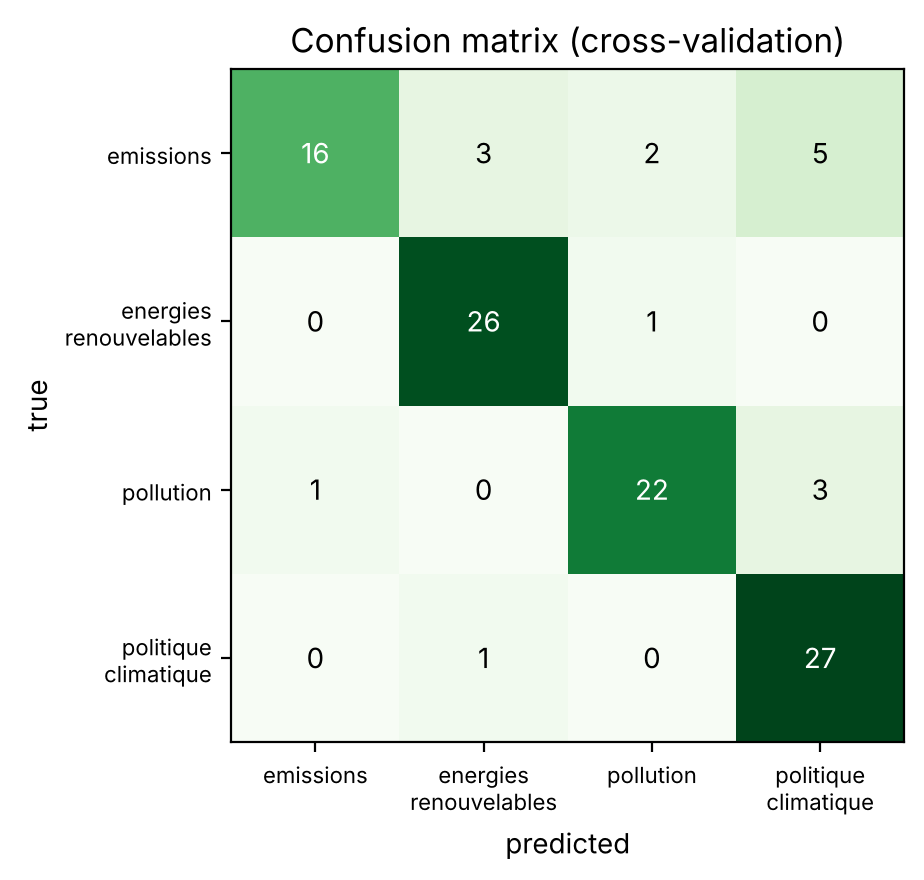

In [8]:
best = table_b.iloc[0]
best_pred = predictions[(best['features'], best['model'])]
print('Best:', best['model'], 'with', best['features'], '\n')
print(classification_report(y, best_pred, digits=3))

import matplotlib.pyplot as plt
cm = confusion_matrix(y, best_pred, labels=CATEGORIES)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap='Greens')
ax.set_xticks(range(4), [c.replace('_', '\n') for c in CATEGORIES], fontsize=8)
ax.set_yticks(range(4), [c.replace('_', '\n') for c in CATEGORIES], fontsize=8)
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title('Confusion matrix (cross-validation)')
plt.tight_layout(); plt.savefig('images/confusion_matrix.png', dpi=120); plt.show()

In [9]:
# Which documents are misclassified, and why?
wrong = [(files[i], kinds[i], labels[i], best_pred[i], titles[i][:60]) for i in range(len(docs)) if best_pred[i] != labels[i]]
pd.DataFrame(wrong, columns=['file', 'kind', 'true', 'predicted', 'title'])

,file,kind,true,predicted,title
0,text07.txt,encyclopedia,emissions,pollution,Protoxyde d'azote
1,text32.txt,encyclopedia,politique_climatique,energies_renouvelables,Agence de l'environnement et de la maîtrise de...
2,text34.txt,encyclopedia,emissions,politique_climatique,Hydrofluorocarbure
3,text40.txt,encyclopedia,emissions,politique_climatique,Marché des quotas carbone
4,text43.txt,encyclopedia,emissions,pollution,Pergélisol
5,text44.txt,encyclopedia,emissions,energies_renouvelables,Sobriété énergétique
6,text66.txt,encyclopedia,pollution,emissions,Monoxyde de carbone
7,text81.txt,news,emissions,politique_climatique,Canada : le gouvernement canadien présente son...
8,text82.txt,news,emissions,politique_climatique,Obama annonce de nouvelles normes pour les véh...
9,text83.txt,news,emissions,energies_renouvelables,Nucléaire : 69 % des Français pensent à tort q...


### Does the classifier work on a *different kind* of text?
The lecture warns that models get worse on text from another domain. We train **only on the 81 encyclopedia texts** and test on the 26 news, discussion and legal texts, which the model never saw.

In [10]:
best_model = models[best['model']]
variant = best['features']
enc = [i for i, k in enumerate(kinds) if k == 'encyclopedia']
oth = [i for i, k in enumerate(kinds) if k != 'encyclopedia']
X_all = [with_bigrams(t) for t in terms[variant]]
pipe = make_pipeline(TfidfVectorizer(analyzer=lambda x: x, sublinear_tf=True), best_model)
pipe.fit([X_all[i] for i in enc], y[enc])
pred_oth = pipe.predict([X_all[i] for i in oth])
print(f'Trained on encyclopedia, tested on other kinds: accuracy = {accuracy_score(y[oth], pred_oth):.3f}, '
      f'macro F1 = {f1_score(y[oth], pred_oth, average="macro"):.3f}')
for kind in ['news', 'discussion', 'legal']:
    idx = [j for j, i in enumerate(oth) if kinds[i] == kind]
    print(f'   {kind:11s} {sum(pred_oth[j] == y[oth][j] for j in idx)}/{len(idx)} correct')

Trained on encyclopedia, tested on other kinds: accuracy = 0.654, macro F1 = 0.566
   news        9/16 correct
   discussion  6/8 correct
   legal       2/2 correct


In [11]:
# The words that the model finds most typical of each topic
pipe_all = make_pipeline(TfidfVectorizer(analyzer=lambda x: x, sublinear_tf=True), LogisticRegression(max_iter=2000, C=10))
pipe_all.fit(X_all, y)
vec, clf = pipe_all[0], pipe_all[1]
names = np.array(vec.get_feature_names_out())
for c, coefs in zip(clf.classes_, clf.coef_):
    print(f'{c:24s}', ', '.join(names[np.argsort(-coefs)[:12]]))

emissions                carbone, co2, émission, serre, gaz, gaz_serre, forêt, atmosphère, fossile, réchauffement, méthane, surface
energies_renouvelables   énergie, éolien, électricité, solaire, renouvelable, photovoltaïque, électrique, production, chaleur, thermique, énergie_éolien, énergie_renouvelable
politique_climatique     accord, européen, loi, nations, climat, convention, unir, union, union_européen, party, nations_unir, action
pollution                pollution, polluant, acide, écosystème, santé, eau, air, toxique, plastique, azote, catastrophe, navire


In [12]:
# Try it on new sentences (written by us, not in the corpus)
new_texts = [
    "Les panneaux photovoltaïques installés sur les toits produisent de l'électricité sans émettre de CO2.",
    "Le Parlement européen a voté une nouvelle loi pour réduire les émissions de 55 % d'ici 2030.",
    "Les rejets d'eaux usées industrielles contaminent la rivière et menacent les poissons.",
    "Le méthane libéré par la fonte du pergélisol accélère le réchauffement de la planète.",
    "Je trouve que cette section de l'article sur les éoliennes manque de sources fiables.",
]
X_new = [with_bigrams(VARIANTS[variant](nlp(t))) for t in new_texts]
proba = pipe_all.predict_proba(X_new)
for t, p in zip(new_texts, proba):
    order = np.argsort(-p)
    print(f'{clf.classes_[order[0]]:24s} ({p[order[0]]:.2f})  <- {t}')

energies_renouvelables   (0.49)  <- Les panneaux photovoltaïques installés sur les toits produisent de l'électricité sans émettre de CO2.
politique_climatique     (0.66)  <- Le Parlement européen a voté une nouvelle loi pour réduire les émissions de 55 % d'ici 2030.
pollution                (0.46)  <- Les rejets d'eaux usées industrielles contaminent la rivière et menacent les poissons.
emissions                (0.47)  <- Le méthane libéré par la fonte du pergélisol accélère le réchauffement de la planète.
energies_renouvelables   (0.37)  <- Je trouve que cette section de l'article sur les éoliennes manque de sources fiables.


**Classification results.**

**The best model is the linear SVM on lemmas** (stems tie): **accuracy 0.850, macro F1 0.844**, far above the baseline (always predicting the biggest class: accuracy 0.243, F1 0.158). Every real model beats the baseline by a lot. Lemmas and stems help a little (+0.02 to +0.06 F1 over plain words).

**Per topic:**
- *energies_renouvelables* is the easiest (F1 0.91).
- *emissions* is the hardest (recall 0.62): emission texts are often classified as *politique_climatique* or *pollution*.

**The errors make sense.** The topics really overlap:
- *Canada : plan de réduction des émissions*, *Marché des quotas carbone* and *Hydrofluorocarbure* (regulated by the Kyoto and Kigali protocols) are about emissions **and** about policy;
- *Protoxyde d'azote* and *Monoxyde de carbone* are both emissions and pollutants.

Each text can really belong to more than one topic, so a **multi-label** classifier would be more correct.

**Another kind of text is harder** (domain dependence, as the lecture warns). Trained only on encyclopedia texts, the model gets **0.654 accuracy** on the news, discussion and legal texts (news 9/16, discussion 6/8, legal 2/2), against 0.85 in cross-validation. News texts talk about events and people rather than definitions, and 7 of the 16 misclassified documents are news or discussions. To improve: **more news and discussion texts** in the training data.

**The most typical words per topic** are very readable:
- *carbone, co2, émission, gaz_serre, méthane* for emissions;
- *éolien, solaire, photovoltaïque, énergie_renouvelable* for renewables;
- *accord, loi, union_européen, convention* for policy;
- *polluant, acide, toxique, plastique, santé* for pollution.

The **bigrams** (*gaz_serre*, *énergie_éolien*) are among the best features. We can also see two lemmatizer errors from Week 3: *nations_unir* (for *Nations unies*) and *party* (an English lemma for *Parties*).

**On new sentences** that we wrote ourselves, all five predictions are correct, though with modest confidence (0.37 to 0.66). Even the talk-page-style sentence about *éoliennes* is correctly put in renewables.

---
# Summary and next steps

| Question | Answer from this notebook |
|---|---|
| Can we find the right documents for a French query? | Yes: Precision@5 0.56 and MRR 0.95 with lemmatization |
| Which preprocessing is best? | Lemmas for precision, stems for recall; stop-word removal alone does not help TF-IDF |
| Can we classify the topic automatically? | Yes: macro F1 0.84, against 0.16 for the baseline |
| Main weaknesses | vocabulary mismatch (*voitures / véhicules*), overlapping topics, other kinds of text |

**What we can add as the course goes on:**
1. **Named entities (next week):** extract organisations, places and dates (*ADEME, GIEC, COP21, Pékin, 2050*) to filter the search results and show them.
2. **Query expansion with synonyms** (WordNet/OMW from Week 3, or word embeddings), to solve *voitures ↔ véhicules*.
3. **BM25**, the ranking formula of real search engines, compared with TF-IDF.
4. **More data:** more news and discussion texts, and the official sources from the project idea (ADEME, vie-publique.fr, EU documents) after checking their licences.
5. **Multi-label classification:** a text can be about emissions **and** policy.
6. Better sentence splitting for the legal texts and discussions (at line breaks), and a list of domain stop words for the talk pages (*article, discussion, répondre*).
7. A small web interface (e.g. Streamlit) where the user types a query and sees the results with their topic.